In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import os

path = kagglehub.dataset_download("deeplumiere/accident-analysis-dataset")
csv_path = os.path.join(path, "accident_data.csv")
df = pd.read_csv(csv_path)

print("--- 1. FIRST 5 ROWS (df.head()) ---")
print(df.head())

print("\n--- 2. DATASET INFO (df.info()) ---")
df.info()

print("\n--- 3. STATISTICAL SUMMARY (df.describe()) ---")
print(df.describe())

print("\n--- 4. MISSING VALUES (df.isnull().sum()) ---")
print(df.isnull().sum())

--- 1. FIRST 5 ROWS (df.head()) ---
           Index Accident_Severity Accident Date   Latitude  \
0  200701BS64157           Serious    05-06-2019  51.506187   
1  200701BS65737           Serious    02-07-2019  51.495029   
2  200701BS66127           Serious    26-08-2019  51.517715   
3  200701BS66128           Serious    16-08-2019  51.495478   
4  200701BS66837            Slight    03-09-2019  51.488576   

              Light_Conditions           District Area  Longitude  \
0        Darkness - lights lit  Kensington and Chelsea  -0.209082   
1                     Daylight  Kensington and Chelsea  -0.173647   
2  Darkness - lighting unknown  Kensington and Chelsea  -0.210215   
3                     Daylight  Kensington and Chelsea  -0.202731   
4        Darkness - lights lit  Kensington and Chelsea  -0.192487   

   Number_of_Casualties  Number_of_Vehicles Road_Surface_Conditions  \
0                     1                   2                     Dry   
1                     1     

In [ ]:
# Data Cleaning & Preprocessing Steps
# 1. Drop rows where critical target or location is missing
df = df.dropna(subset=['Accident_Severity', 'Latitude', 'Longitude'])

# 2. Impute categorical missing values with 'Unknown'
df['Road_Surface_Conditions'].fillna('Unknown', inplace=True)
df['Road_Type'].fillna('Unknown', inplace=True)
df['Weather_Conditions'].fillna('Unknown', inplace=True)
df['Urban_or_Rural_Area'].fillna('Unknown', inplace=True)

# 3. Convert 'Accident Date' (with space) to datetime
df['Accident_Date'] = pd.to_datetime(df['Accident Date'], format='%d-%m-%Y', errors='coerce')
df['Year'] = df['Accident_Date'].dt.year
df['Month'] = df['Accident_Date'].dt.month
df['YearMonth'] = df['Accident_Date'].dt.to_period('M').astype(str)

(array([-20.,   0.,  20.,  40.,  60.,  80., 100.]),
 [Text(-20.0, 0, '2024-05'),
  Text(0.0, 0, '2019-01'),
  Text(20.0, 0, '2020-09'),
  Text(40.0, 0, '2022-05'),
  Text(60.0, 0, '2024-01'),
  Text(80.0, 0, '2025-09'),
  Text(100.0, 0, '')])

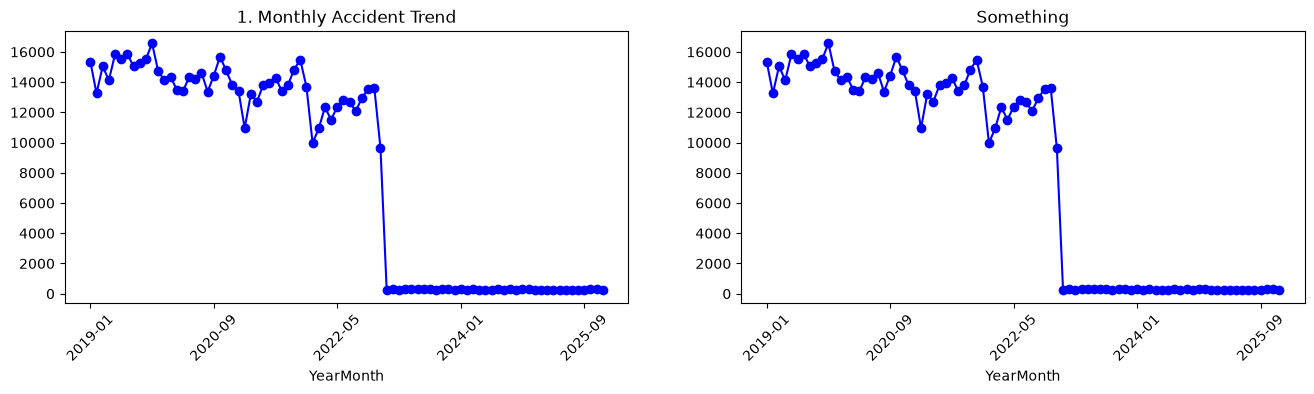

In [ ]:
# Number of Accidents and Accident Severity by Season 

# Filter dataframe by seasons
winter_data = df[df['date'].dt.month.isin([12, 1, 2])]
spring_data = df[df['date'].dt.month.isin([3, 4, 5])]
summer_data = df[df['date'].dt.month.isin([6, 7, 8])]
fall_data = df[df['date'].dt.month.isin([9, 10, 11])]



plt.figure(figsize=(16, 12))
plt.subplot(3, 2, 1)
monthly_counts = df.groupby('YearMonth').size()
monthly_counts.plot(kind='line', marker='o', color='b')
plt.title('1. Monthly Accident Trend')
plt.xticks(rotation=45)

plt.subplot(3, 2, 2)
monthly_counts = df.groupby('YearMonth').size()
monthly_counts.plot(kind='line', marker='o', color='b')
plt.title('Something')
plt.xticks(rotation=45)